## Quantitative Analysis of Educational Achievement in Bulgarian Language and Literature and Mathematics Across Schools in Varna
### An Investigation of Trends, Educational Stratification, Outliers, and Correlations Over Time

#### Abstract
The results of the National External Assessment (NEA) in Bulgarian Language and Literature (BLL) and Mathematics (Math) in Varna reveal a persistent and widening gap between a small elite group of schools and the rest of the educational institutions. While achievement in BLL appears more stable and exhibits lower variation, Mathematics is the main driver of educational inequality in the city, showing greater sensitivity to year-to-year cohorts and higher dispersion.

#### Introduction
This analysis examines the academic performance of schools in the city of Varna based on historical examination data in BLL and Mathematics. The main objective is to apply descriptive statistics, regression analysis, and parametric and non-parametric tests to determine:

- What are the overall achievement levels and distributions across the city and among the 15 top-performing schools?
- Is there a stable correlation between performance in humanities and STEM subjects?
- Does Simpson's paradox occur when the data are aggregated across years?
- To what extent is the gap widening between the highest-performing and at-risk schools (using the IQR ratio, CV, and OLS slopes)?

### Methodology and Step-by-Step Analysis

#### 1. Loading Libraries and Initial Data Inspection
For the analysis, we use pandas for tabular data manipulation, numpy for mathematical operations, matplotlib for visualizations, and scipy.stats for statistical tests.

We import the required modules, load the Excel file `data/data.xlsx`, and display key metrics describing the dataset: the total number of records, the number of unique schools, and the period covered by the analysis (years).

In [50]:
# 0. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.stats import f_oneway

# 1. Load the Excel file
file_path = 'data/data.xlsx'
df = pd.read_excel(file_path)

print(f"Total number of records: {len(df)}")
print(f"Unique schools: {df['School'].nunique()}")
print(f"Available years: {df['Year'].unique()}")

Total number of records: 320
Unique schools: 40
Available years: <StringArray>
['2020-2021', '2021-2022', '2022-2023', '2025-2026', '2019-2020', '2018-2019',
 '2023-2024', '2024-2025']
Length: 8, dtype: str


#### 2. Descriptive Statistics for the Entire City
To understand the overall level of achievement, we calculate the main descriptive statistics (moments) for BLL and Mathematics across the entire city.

**Formulas used:**

**Arithmetic mean** ($\mu$ / mean):
$$\bar{X} = \frac{1}{N} \sum_{i=1}^{N} X_i$$

**Median:** The value that divides the ordered sample into two equal halves (the 50th percentile). It is robust to extreme values (outliers).

**Standard deviation** ($s$ / std):
$$s = \sqrt{\frac{1}{N-1} \sum_{i=1}^{N} (X_i - \bar{X})^2}$$
It measures the absolute dispersion of the results around the mean.

**Minimum (min) and maximum (max):** The lowest and highest values in the sample.

**Why we use them:** To gain an initial understanding of the level of achievement in the city and determine whether the results are homogeneous or highly polarized.

**What they tell us about our data:** The arithmetic mean ($\bar{X}$) and the median indicate the centre of the achievement distribution. If the median is considerably lower than the mean, this may suggest that a small group of very high-performing schools is pulling the average upward while most schools score below it. The standard deviation ($s$) and the range (min–max) reveal the scale of inequality — the point difference between the lowest- and highest-performing schools in Varna.

In [51]:
# 2. Overall statistics for the entire city (all schools)
print("=== CITY-WIDE STATISTICS (All Schools) ===")
city_stats = df[['BLL', 'MATH']].agg(['mean', 'median', 'std', 'min', 'max'])
display(city_stats.round(2))
print("\n" + "="*50 + "\n")

=== CITY-WIDE STATISTICS (All Schools) ===


,BLL,MATH
mean,60.99,45.51
median,64.18,44.88
std,16.60,17.96
min,7.58,8.82
max,93.22,96.95


**Analytical Findings (What Do We See in Our Data?)**

**A substantial difference in baseline achievement between subjects:** The mean score in Bulgarian Language and Literature (60.99 points) is approximately 15.5 points higher than the mean score in Mathematics (45.51 points). This indicates that the Mathematics examination is considerably more challenging for students in Varna and that overall mastery of the subject is lower.

**Greater dispersion in Mathematics:** The standard deviation in Mathematics ($s = 17.96$) is higher than in BLL ($s = 16.60$). This indicates that results in the STEM subject are more widely dispersed and polarized, whereas achievement in the humanities subject is more homogeneous.

**The full range of the scoring scale is represented:** Both the minimum values (below 9 points) and the maximum values (above 93–96 points) show that the sample includes both very low-performing school cohorts and top achievers, spanning almost the entire examination scale.

#### 3. Identifying and Visualizing the Top 15 Schools
We group the data by school, calculate the average combined score $\frac{\bar{X}_{BLL} + \bar{X}_{Math}}{2}$ over the entire period, and identify the 15 highest-performing schools in Varna.

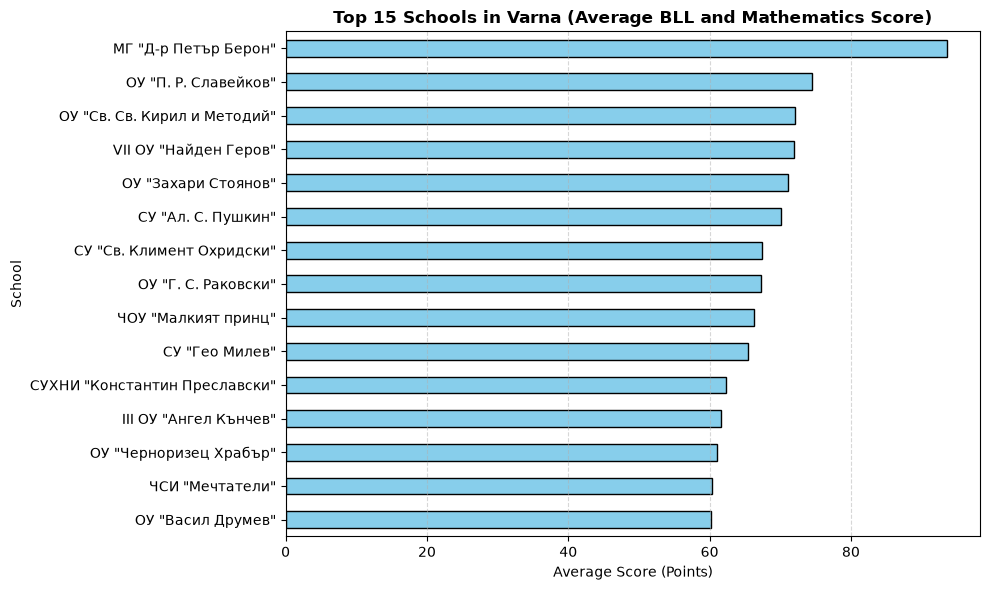

In [52]:
# 3. Identify the top 15 schools based on the average score (BLL + Mathematics) for the entire period and plot the results
school_avg = df.groupby('School')[['BLL', 'MATH']].mean().mean(axis=1).sort_values(ascending=False)
top_15_schools = school_avg.head(15).index.tolist()

# 3.1 Visualize the top 15 schools (horizontal bar chart)
top_15_values = school_avg.head(15).sort_values(ascending=True)
plt.figure(figsize=(10, 6))
top_15_values.plot(kind='barh', color='skyblue', edgecolor='black')
plt.title('Top 15 Schools in Varna (Average BLL and Mathematics Score)', fontweight='bold')
plt.xlabel('Average Score (Points)')
plt.ylabel('School')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### 4. Filtering and Descriptive Statistics for the Top 15 Schools
We filter the original DataFrame to include only the top 15 schools and recalculate the descriptive statistics (mean, median, std, min, max). This allows us to compare the characteristics of the elite group with the overall city-wide values.

In [53]:
# 4. Filter the main DataFrame to include only these top 15 schools
df_top15 = df[df['School'].isin(top_15_schools)]
print(f"Number of rows in the filtered top 15 schools dataset: {len(df_top15)}")

# 5. Calculate the main statistics for the top 15 schools
print("\n=== STATISTICS FOR THE TOP 15 SCHOOLS ONLY ===")
top15_stats = df_top15[['BLL', 'MATH']].agg(['mean', 'median', 'std', 'min', 'max'])
display(top15_stats.round(2))
print("\n" + "="*50 + "\n")

Number of rows in the filtered top 15 schools dataset: 120

=== STATISTICS FOR THE TOP 15 SCHOOLS ONLY ===


,BLL,MATH
mean,74.57,62.13
median,74.37,61.24
std,6.32,12.78
min,59.77,28.86
max,93.22,96.95


**Analytical Findings (What Do We See in Our Data?)**

**A significant increase compared with the city-wide averages:** The mean BLL score among the top 15 schools (74.57 points) is approximately 13.6 points higher than the city-wide mean (60.99 points), while the Mathematics mean (62.13 points) exceeds the city-wide mean (45.51 points) by more than 16.6 points. This indicates the existence of a clearly defined elite educational tier in Varna.

**Substantially lower dispersion (greater homogeneity) in BLL:** The standard deviation in BLL among the top 15 schools is only 6.32 points (compared with 16.60 points for the entire city). This suggests that results in the humanities subject are tightly clustered, stable, and predictable among the elite schools.

**Continued internal polarization in Mathematics:** Although these schools belong to the top 15, dispersion in Mathematics remains high ($s = 12.78$ points), and the minimum score falls to 28.86 points. This reveals an important finding: even among the city's best schools, some cohorts perform considerably worse in STEM, whereas the lower end in BLL is much higher (a minimum of 59.77 points).

#### 5. Comparison of BLL vs Mathematics Results for the Top 15 Schools Against the City-Wide Average
**What it does:** Shows the distribution of scores in each subject for every school in the top 15. A dotted reference line represents the overall city-wide average score.

**Reference-line formula:**
$$\text{Overall City Mean} = \frac{\bar{X}_{City, BLL} + \bar{X}_{City, Math}}{2}$$

**Why we use it:** To analyze the specific performance profile of the leading schools in Varna and measure precisely how far they are ahead of the overall city-wide level.

**What it shows about our data:** It allows us to determine whether leading schools maintain a balance between humanities and STEM subjects or are strongly specialized (for example, high BLL scores but weaker Mathematics results).

The reference line for the overall city mean visualizes the so-called **educational premium** — the score difference between a student in an elite school and the average result across the city.

<Figure size 1400x700 with 0 Axes>

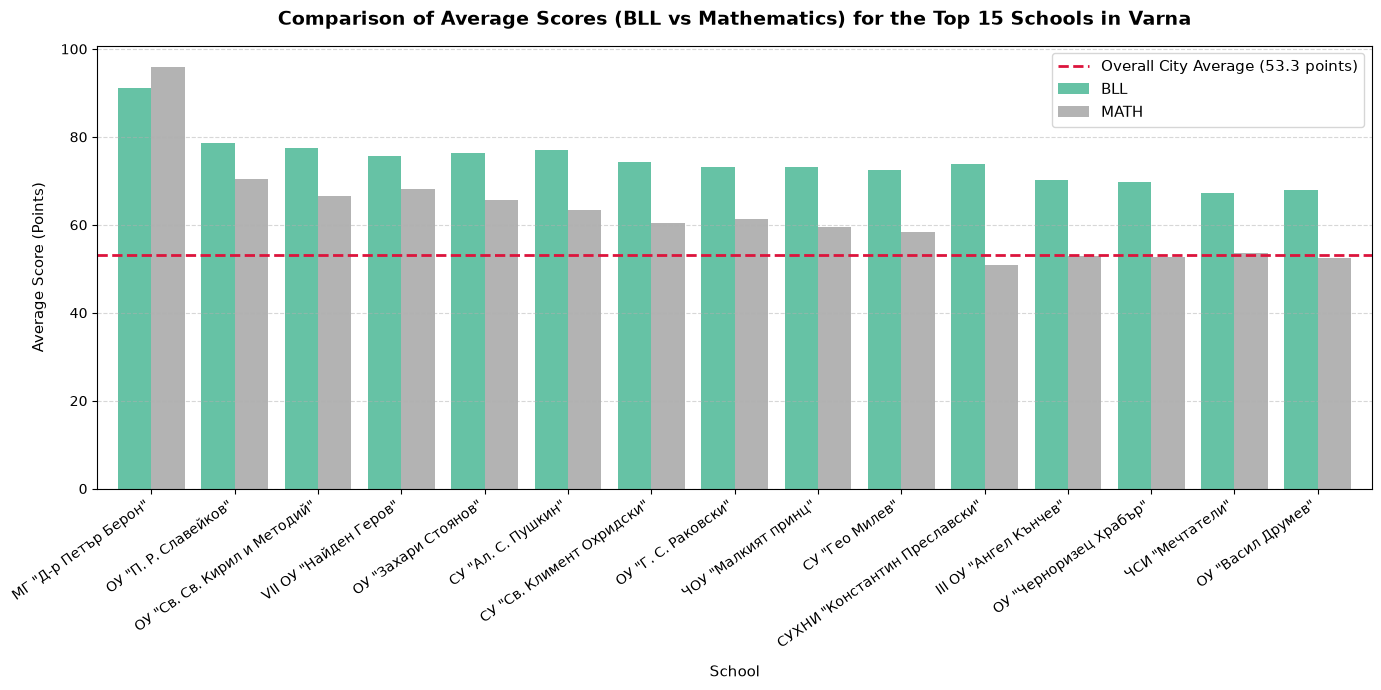

In [54]:
# 6. Retrieve the mean values directly from the table for the reference line
city_avg_bel = city_stats.loc['mean', 'BLL']
city_avg_mat = city_stats.loc['mean', 'MATH']
overall_city_mean = (city_avg_bel + city_avg_mat) / 2

# 6.1 Prepare the data for the chart
top_15_barplot_data = df_top15.groupby('School')[['BLL', 'MATH']].mean().loc[top_15_schools]

plt.figure(figsize=(14, 7))
ax = top_15_barplot_data.plot(kind='bar', figsize=(14, 7), colormap='Set2', width=0.8)

# 6.2 Add a red reference line for the overall city-wide average
plt.axhline(y=overall_city_mean, color='crimson', linestyle='--', linewidth=2, 
            label=f'Overall City Average ({overall_city_mean:.1f} points)')

# 6.3 Chart settings
plt.title('Comparison of Average Scores (BLL vs Mathematics) for the Top 15 Schools in Varna', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('School', fontsize=11, labelpad=10)
plt.ylabel('Average Score (Points)', fontsize=11, labelpad=10)
plt.xticks(rotation=35, ha='right', fontsize=10)
plt.legend(fontsize=11, frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Analytical Findings (What Do We See in Our Data?)**

**All schools are above the city-wide average:** Every school included in the top 15 remains clearly above the red reference line (the overall Varna average of 53.25 points). This confirms that the selected elite group consists of institutions with distinctly above-average academic performance.

**A clear BLL advantage over Mathematics within the elite group:** Although these schools are leaders, the average BLL score is higher than the Mathematics score in almost every case. The only exception is the absolute leader (e.g. Dr. Petar Beron Mathematics High School), where Mathematics surpasses or comes very close to the exceptionally high BLL level (approximately 96 vs. 91 points, respectively).

**Homogeneity in humanities compared with stratification in STEM:** The BLL bars among the top 15 are relatively close and consistent across the group (around 70–80+ points), whereas the Mathematics bars show a steeper ranking and a sharp decline toward the bottom of the top 15. This again indicates that Mathematics is the key differentiating factor even among the best schools.

#### 6. Trend Analysis of Overall Achievement by Year for the Top 15 Schools
**What it does:** Tracks changes over time in the combined average achievement score by year.

**Formula for the overall score of school $j$ in year $t$:**
$$Y_{j,t} = \frac{\text{BLL}_{j,t} + \text{Math}_{j,t}}{2}$$

**Why we use it:** To track changes over time and assess the institutional stability of the elite group.

**What it shows about our data:** It indicates whether the top 15 is a stable classification throughout the study period or whether some schools experience sharp rises and falls depending on the characteristics of individual cohorts.

It also helps distinguish schools with consistently high performance from those whose good results may have been situational (a single high-performing cohort).

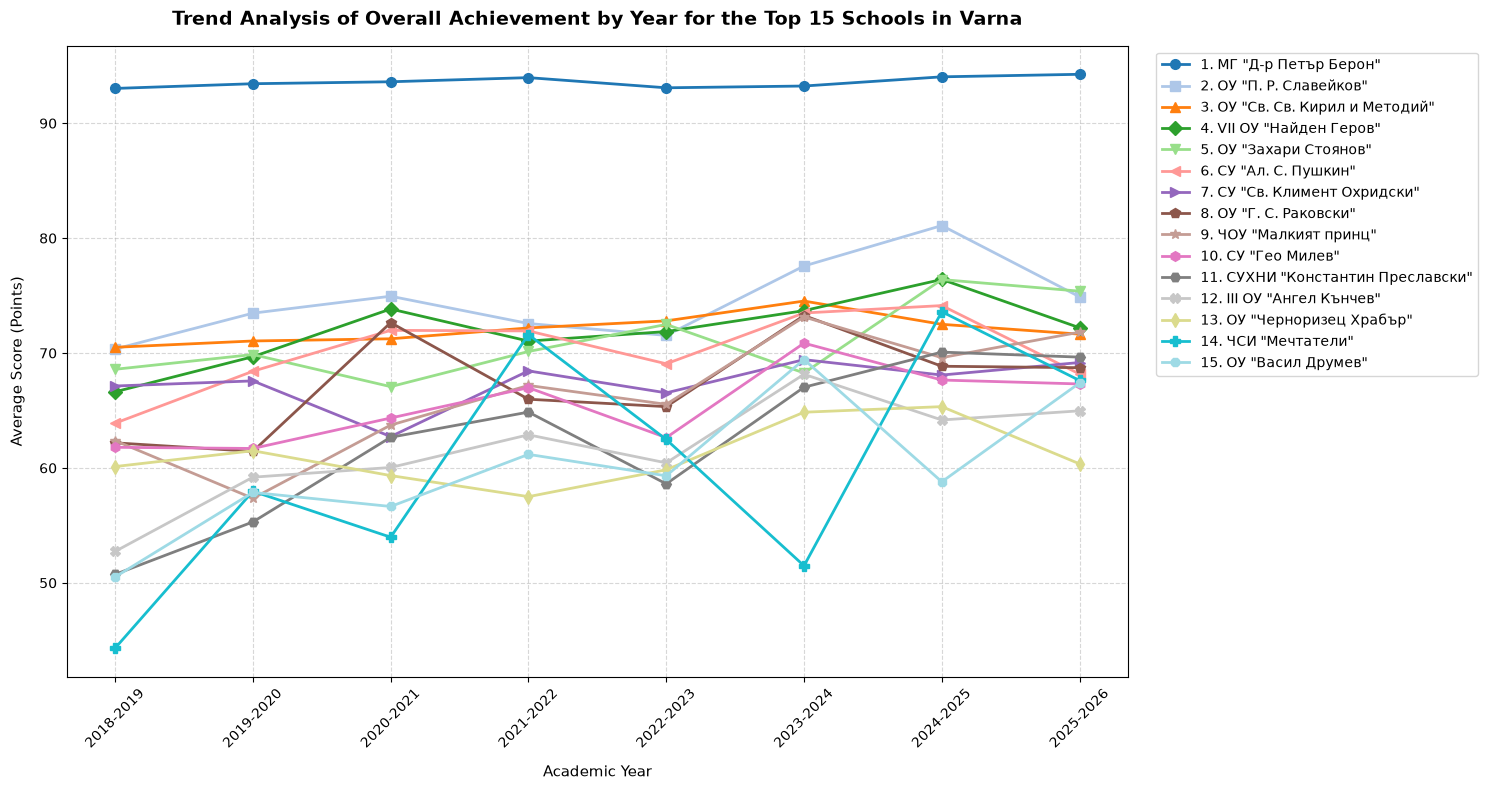

In [55]:
# 7.1 Calculate the overall score (BLL + Mathematics) by year for each school
df_top15['Overall_Score'] = (df_top15['BLL'] + df_top15['MATH']) / 2
trend_pivot = df_top15.pivot_table(index='Year', columns='School', values='Overall_Score')

sorted_schools = top_15_schools 
trend_pivot = trend_pivot[sorted_schools]

plt.figure(figsize=(15, 8))
colors = plt.cm.tab20(np.linspace(0, 1, len(sorted_schools)))
markers = ['o', 's', '^', 'D', 'v', '<', '>', 'p', '*', 'h', 'H', 'X', 'd', 'P', '8']

for i, school in enumerate(sorted_schools):
    plt.plot(trend_pivot.index, trend_pivot[school], 
             label=f"{i+1}. {school}", 
             color=colors[i], 
             marker=markers[i % len(markers)], 
             linewidth=2, 
             markersize=7)

plt.title('Trend Analysis of Overall Achievement by Year for the Top 15 Schools in Varna', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Academic Year', fontsize=11, labelpad=10)
plt.ylabel('Average Score (Points)', fontsize=11, labelpad=10)
plt.xticks(rotation=45, fontsize=10)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10, frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Analytical Findings (What Do We See in Our Data?)**

**An undisputed leader with exceptional stability:** Dr. Petar Beron Mathematics High School holds a clear first place (with an average combined score of nearly 93.6 points) and also shows a minimal standard deviation across years (only 0.46 points). This indicates exceptional institutional consistency and a very high level of achievement, regardless of differences between cohorts.

**A clear hierarchy and stratification within the elite group:** The chart shows that the top 15 schools do not form a homogeneous group. Instead, they are divided into several subgroups: a distinct leader (the Mathematics High School), a strong middle group (schools scoring between 67 and 75 points), and a group of institutions at the lower end of the top 15 (around 60 points).

**Different levels of stability over time (cohort volatility):** While leading primary and language schools maintain relatively smooth trend lines, some schools (such as private schools or schools with specialized classes) show greater volatility (a standard deviation across years of more than 6–10 points). This suggests that their performance is more sensitive to changes in the quality or preparation of individual cohorts.

#### 7. Pearson Correlation Analysis Between BLL and Mathematics
**What it does:** Calculates Pearson's linear correlation coefficient ($r$) and creates a scatter plot with a linear trend line.

**Formula for Pearson's correlation coefficient ($r_{X,Y}$):**
$$r_{X,Y} = \frac{\sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})}{\sqrt{\sum_{i=1}^{n} (X_i - \bar{X})^2} \sqrt{\sum_{i=1}^{n} (Y_i - \bar{Y})^2}}$$

**Why we use it:** To test the hypothesis that schools performing well in humanities (BLL) also achieve high results in STEM (Mathematics).

**What it shows about our data:** Pearson's coefficient indicates the strength and direction of the relationship. A strongly positive correlation ($r \to 1$) indicates institutional consistency — high-performing schools perform well across both subjects. A weak correlation would suggest subject-specific specialization or differences in schools' educational profiles.

--- CORRELATION MATRIX (BLL vs Mathematics) ---


,BLL,MATH
BLL,1.0000,0.8959
MATH,0.8959,1.0000



Pearson correlation coefficient between BLL and Mathematics: 0.90


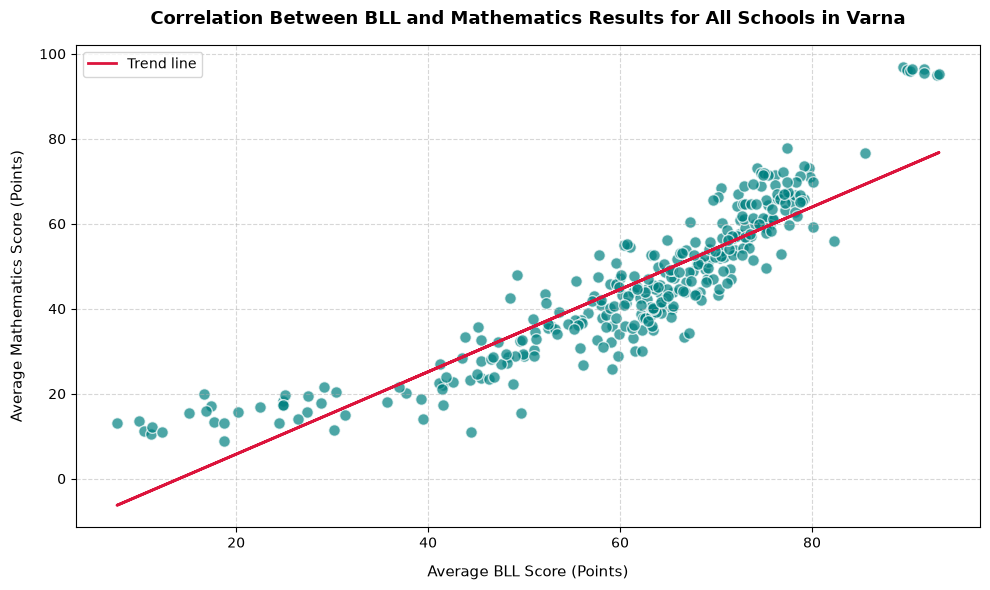

In [56]:
# 8.1 Calculate the correlation matrix
correlation_matrix = df[['BLL', 'MATH']].corr(method='pearson')
print("--- CORRELATION MATRIX (BLL vs Mathematics) ---")
display(correlation_matrix.round(4))

corr_value = correlation_matrix.loc['BLL', 'MATH']
print(f"\nPearson correlation coefficient between BLL and Mathematics: {corr_value:.2f}")

# 8.2 Visualization using a scatter plot and trend line
plt.figure(figsize=(10, 6))
plt.scatter(df['BLL'], df['MATH'], alpha=0.7, color='teal', s=70, edgecolors='w')

m, b = np.polyfit(df['BLL'], df['MATH'], 1)
plt.plot(df['BLL'], m*df['BLL'] + b, color='crimson', linewidth=2, label='Trend line')

plt.title('Correlation Between BLL and Mathematics Results for All Schools in Varna', fontsize=13, pad=15, fontweight='bold')
plt.xlabel('Average BLL Score (Points)', fontsize=11, labelpad=10)
plt.ylabel('Average Mathematics Score (Points)', fontsize=11, labelpad=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Analytical Findings (What Do We See in Our Data?)**

**An exceptionally strong positive linear relationship:** A coefficient close to 0.90 indicates a very strong positive correlation between BLL and Mathematics results in Varna schools. This suggests that institutions achieving high results in humanities also perform very well in STEM.

**Institutional consistency in educational preparation:** The high correlation indicates no substantial specialization at the expense of either subject. The educational profile of schools in the city is broad and consistent — high-performing schools maintain high standards in both areas.

**A clear linear trend:** The scatter plot and red trend line show a relatively even distribution around the line, supporting the conclusion that a linear relationship describes the association between the two examination components very well.

#### 8. Analysis of Distribution Moments (Skewness and Kurtosis)
**What it does:** Calculates the third and fourth central moments to assess the shape of the distribution.

**Formulas:**

**Skewness ($S_k$):**
$$S_k = \frac{\frac{1}{N}\sum_{i=1}^{N}(X_i - \bar{X})^3}{s^3}$$
- $S_k < 0$: Negative (left) skewness — concentration of high scores.
- $S_k > 0$: Positive (right) skewness — concentration of low scores.

**Kurtosis ($K$):**
$$K = \frac{\frac{1}{N}\sum_{i=1}^{N}(X_i - \bar{X})^4}{s^4} - 3$$
- $K > 0$ (leptokurtic): pronounced extreme values (heavy tails).
- $K < 0$ (platykurtic): a flatter distribution without sharp peaks.

**Why we use them:** To determine whether school performance follows a normal (symmetric) Gaussian distribution or is skewed toward exceptionally high or low achievement.

**What they show about our data:** Skewness indicates where most results are concentrated. Negative skewness means that most schools perform above the average, while a long tail of at-risk schools pulls the distribution downward.

Kurtosis indicates whether results are concentrated around the mean (a sharp peak) or spread across the extremes (very strong and very weak schools at the same time).

 DISTRIBUTION MOMENTS ANALYSIS FOR SCHOOLS IN VARNA 

1. BULGARIAN LANGUAGE AND LITERATURE (BLL):
   - Skewness (Skewness = -1.1434)
   - Kurtosis (Kurtosis = 1.2844)

2. MATHEMATICS:
   - Skewness (Skewness = 0.2490)
   - Kurtosis (Kurtosis = 0.1427)


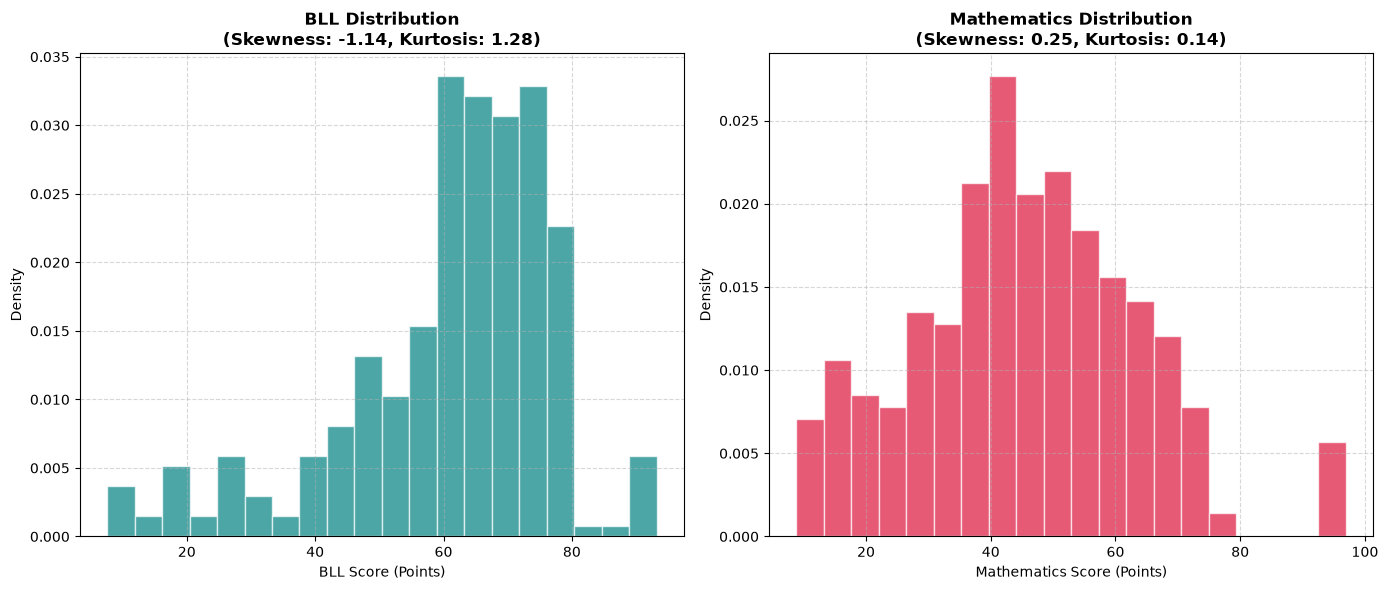

In [57]:
# 9. Calculate skewness and kurtosis with automatic interpretation
skew_bel = df['BLL'].skew()
skew_mat = df['MATH'].skew()
kurt_bel = df['BLL'].kurtosis()
kurt_mat = df['MATH'].kurtosis()

print("=" * 60)
print(" DISTRIBUTION MOMENTS ANALYSIS FOR SCHOOLS IN VARNA ")
print("=" * 60)

print(f"\n1. BULGARIAN LANGUAGE AND LITERATURE (BLL):")
print(f"   - Skewness (Skewness = {skew_bel:.4f})")
print(f"   - Kurtosis (Kurtosis = {kurt_bel:.4f})")

print(f"\n2. MATHEMATICS:")
print(f"   - Skewness (Skewness = {skew_mat:.4f})")
print(f"   - Kurtosis (Kurtosis = {kurt_mat:.4f})")
print("=" * 60)

# 10. Visualize the distributions using histograms
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.hist(df['BLL'].dropna(), bins=20, density=True, color='teal', alpha=0.7, edgecolor='white')
plt.title(f'BLL Distribution\n(Skewness: {skew_bel:.2f}, Kurtosis: {kurt_bel:.2f})', fontsize=12, fontweight='bold')
plt.xlabel('BLL Score (Points)')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
plt.hist(df['MATH'].dropna(), bins=20, density=True, color='crimson', alpha=0.7, edgecolor='white')
plt.title(f'Mathematics Distribution\n(Skewness: {skew_mat:.2f}, Kurtosis: {kurt_mat:.2f})', fontsize=12, fontweight='bold')
plt.xlabel('Mathematics Score (Points)')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Analytical Findings (What Do We See in Our Data?)**

**Strong negative skewness in BLL compared with an almost symmetric Mathematics distribution:** The negative BLL skewness value (-1.14) indicates pronounced left skewness — results are concentrated toward the high end, meaning that most schools achieve high scores while a relatively small group of institutions with low scores forms the left tail. In contrast, the Mathematics distribution is almost symmetric and balanced around the mean ($S_k \approx 0.25$).

**A leptokurtic distribution (a sharp peak and extreme values) in BLL:** The positive and relatively high BLL kurtosis (1.28) indicates a sharper peak and heavier tails, suggesting a concentration of results around the mean alongside distinct extreme values. Mathematics kurtosis is close to zero (0.14), indicating a smoother, approximately normal distribution of scores.

#### 9. Central Limit Theorem (CLT) Simulation
**What it does:** Demonstrates a fundamental principle of statistics: regardless of the original data distribution, the distribution of sample means from repeated independent samples ($n=10$, $B=1000$ repetitions) tends toward a normal distribution ($\mathcal{N}(\mu, \frac{\sigma^2}{n})$).

**Why we use it:** To simulate sample behaviour and demonstrate the statistical reliability of our observations.

**What it shows about our data:** Regardless of how irregular or dispersed the results across individual schools may be, the theorem states that the sample means tend toward a normal distribution. This provides a basis for applying other parametric statistical tests, subject to their assumptions.

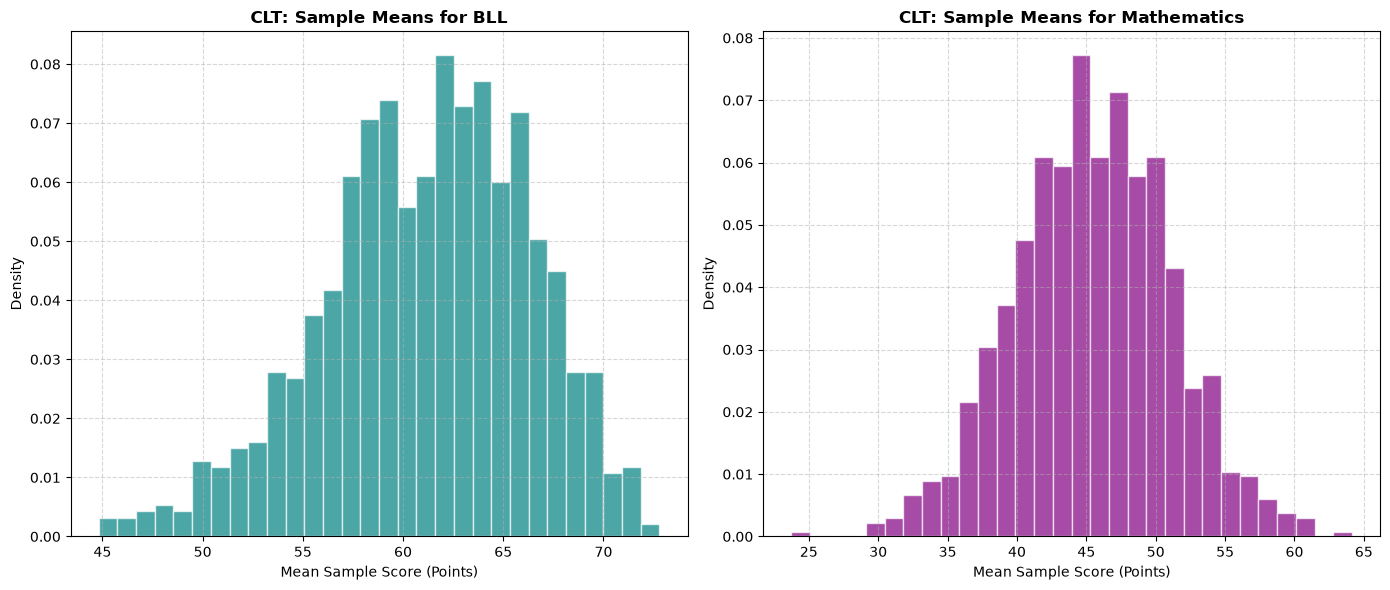

In [58]:
pop_bel = df['BLL'].dropna()
pop_mat = df['MATH'].dropna()

sample_size = 10       
num_samples = 1000     

np.random.seed(42) # for reproducibility
bel_sample_means = [np.mean(np.random.choice(pop_bel, size=sample_size, replace=True)) for _ in range(num_samples)]
mat_sample_means = [np.mean(np.random.choice(pop_mat, size=sample_size, replace=True)) for _ in range(num_samples)]

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.hist(bel_sample_means, bins=30, density=True, color='teal', alpha=0.7, edgecolor='white')
plt.title('CLT: Sample Means for BLL', fontsize=12, fontweight='bold')
plt.xlabel('Mean Sample Score (Points)')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
plt.hist(mat_sample_means, bins=30, density=True, color='purple', alpha=0.7, edgecolor='white')
plt.title('CLT: Sample Means for Mathematics', fontsize=12, fontweight='bold')
plt.xlabel('Mean Sample Score (Points)')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Analytical Findings (What Do We See in Our Data?)**

**Empirical illustration of the Central Limit Theorem:** Although the original distribution of school results is skewed (especially for BLL), the simulation with 1,000 repeated samples of size $n=10$ produces well-shaped, symmetric, approximately normal distributions of sample means. This illustrates that sample means in our dataset are relatively stable and predictable.

**Preservation of the central tendency:** The means of the sampling distributions (61.23 for BLL and 45.36 for Mathematics) are very close to the population means for the full dataset (60.99 and 45.51, respectively), supporting the representativeness of the sampling procedure.

**Rationale for subsequent statistical tests:** The approximately normal sampling distributions demonstrated by the simulation provide a rationale for using parametric tests (such as ANOVA and regression analysis), while their assumptions should still be considered.

#### 10. Outlier Detection and Visualization Using the IQR Method
**What it does:** Identifies schools with unusually extreme results using the interquartile range (IQR) rule.

**Formulas:**
$$IQR = Q_3 - Q_1$$
$$\text{Lower Bound} = Q_1 - 1.5 \times IQR$$
$$\text{Upper Bound} = Q_3 + 1.5 \times IQR$$

Values outside these bounds are considered statistical outliers and are marked on the box plots.

**Why we use it:** To identify statistical anomalies — schools whose results fall outside the expected range.

**What it shows about our data:** It helps identify “exceptional outliers” (schools with exceptionally high results compared with the city-wide context) and “critical outliers” (schools with concerningly low results) that may require management attention and targeted support.

BLL Outliers: 21 (Lower: 27.01, Upper: 99.81)
Mathematics Outliers: 8 (Lower: -0.12, Upper: 91.65)


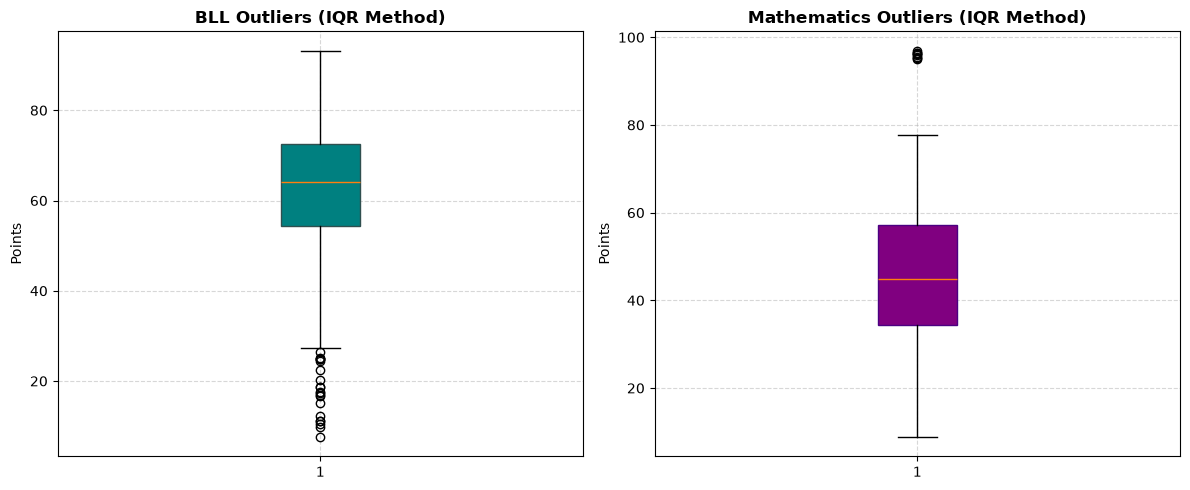

In [59]:
def find_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

outliers_bel, low_b_bel, up_b_bel = find_outliers(df, 'BLL')
outliers_mat, low_b_mat, up_b_mat = find_outliers(df, 'MATH')

print(f"BLL Outliers: {len(outliers_bel)} (Lower: {low_b_bel:.2f}, Upper: {up_b_bel:.2f})")
print(f"Mathematics Outliers: {len(outliers_mat)} (Lower: {low_b_mat:.2f}, Upper: {up_b_mat:.2f})")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.boxplot(df['BLL'].dropna(), patch_artist=True, 
            boxprops=dict(facecolor='teal', color='darkslategray'),
            flierprops=dict(marker='o', color='crimson', markersize=6))
plt.title('BLL Outliers (IQR Method)', fontsize=12, fontweight='bold')
plt.ylabel('Points')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
plt.boxplot(df['MATH'].dropna(), patch_artist=True, 
            boxprops=dict(facecolor='purple', color='indigo'),
            flierprops=dict(marker='o', color='crimson', markersize=6))
plt.title('Mathematics Outliers (IQR Method)', fontsize=12, fontweight='bold')
plt.ylabel('Points')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Analytical Findings (What Do We See in Our Data?)**

**An asymmetric distribution of outliers across subjects:**

In BLL, all 21 outliers are at the lower end of the scale (schools with unusually low results compared with the majority). This supports the skewness finding: overall achievement is high, but a relatively distinct group of institutions experiences serious difficulties in the humanities subject.

In Mathematics, all outliers are at the upper end (8 in total). These are high-achieving schools (such as Dr. Petar Beron Mathematics High School) whose results considerably exceed the upper statistical bound and stand apart from the city-wide average.

**Visualization using box plots:** The charts clearly show the whiskers and individual red points (outliers), indicating that the Mathematics distribution has extreme high values (an elite-level peak), whereas the BLL distribution is skewed toward low-performing schools.

#### 11. One-Way Analysis of Variance (ANOVA) by Year
**What it does:** Tests the null hypothesis ($H_0$) that the city's mean results are identical across all years included in the analysis ($M_{2018} = M_{2019} = \dots = M_{2024}$).

**Formula for the F-statistic:**
$$F = \frac{MS_{between}}{MS_{within}} = \frac{\frac{SS_{between}}{k-1}}{\frac{SS_{within}}{N-k}}$$

**Why we use it:** To test whether the results of Varna schools change significantly over time.

**What it shows about our data:** If ANOVA indicates statistical significance ($p < 0.05$), this suggests that examination difficulty or the educational environment may differ between years, resulting in changes in performance rather than a static equilibrium.

=== ANOVA TEST BY YEAR ===
Mathematics: F = 2.2372, p-value = 3.1179e-02
BLL:        F = 0.4202, p-value = 8.8949e-01


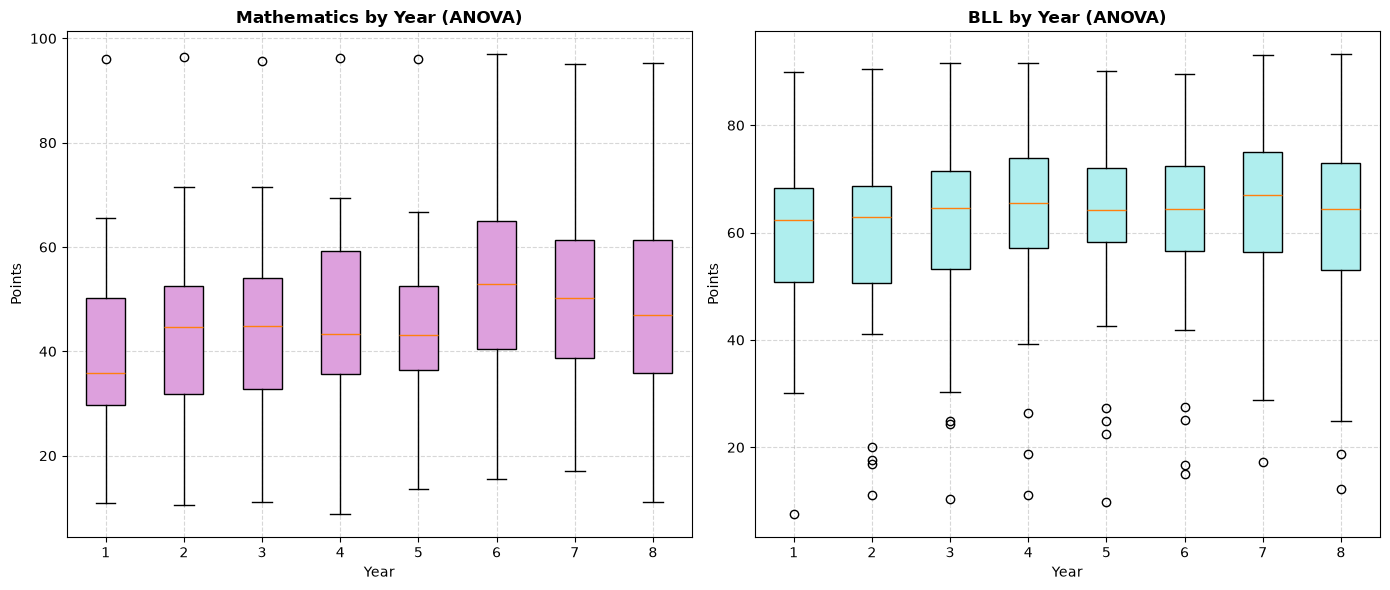

In [60]:
years = sorted(df['Year'].dropna().unique())

groups_mat = [df[df['Year'] == year]['MATH'].dropna() for year in years]
groups_bel = [df[df['Year'] == year]['BLL'].dropna() for year in years]

f_stat_mat, p_val_mat = f_oneway(*groups_mat)
f_stat_bel, p_val_bel = f_oneway(*groups_bel)

print("=== ANOVA TEST BY YEAR ===")
print(f"Mathematics: F = {f_stat_mat:.4f}, p-value = {p_val_mat:.4e}")
print(f"BLL:        F = {f_stat_bel:.4f}, p-value = {p_val_bel:.4e}")

# Visualize box plots by year
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.boxplot(groups_mat, label=years, patch_artist=True, boxprops=dict(facecolor='plum'))
plt.title('Mathematics by Year (ANOVA)', fontweight='bold')
plt.xlabel('Year'); plt.ylabel('Points')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
plt.boxplot(groups_bel, label=years, patch_artist=True, boxprops=dict(facecolor='paleturquoise'))
plt.title('BLL by Year (ANOVA)', fontweight='bold')
plt.xlabel('Year'); plt.ylabel('Points')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Analytical Findings (What Do We See in Our Data?)**

**Statistically significant changes in Mathematics over the years:** Since the p-value for Mathematics (0.0312) is below the conventional significance threshold of $\alpha = 0.05$, we reject the null hypothesis. This indicates statistically significant differences in Mathematics results between academic years. In other words, examination difficulty or the preparation of cohorts in STEM changes over time.

**No statistically significant differences in BLL:** In contrast to Mathematics, the p-value for Bulgarian Language and Literature is very high (0.889), meaning that the null hypothesis cannot be rejected. BLL results are relatively stable across the years — the average achievement level in the humanities subject does not show significant variation between cohorts in Varna.

#### 12. Cumulative Distribution Function (CDF) and Probability Density Function (PDF)
**What it does:** Shows both the differential distribution (histogram/density — PDF) and the cumulative distribution (CDF) of the results.

**CDF formula:**
$$F(x) = P(X \le x)$$

**Why we use them:** To obtain an overall view of the score distribution and make percentile-based assessments.

**What they show about our data:**

The probability density (PDF) shows where schools are concentrated (the peaks of the graph).

The cumulative distribution function (CDF) answers questions such as: “What percentage of schools in Varna have a score below 50 points?” or “Where is the threshold for the lowest-performing 10% of schools?” It visualizes the progression from low to high results across the city's educational system.

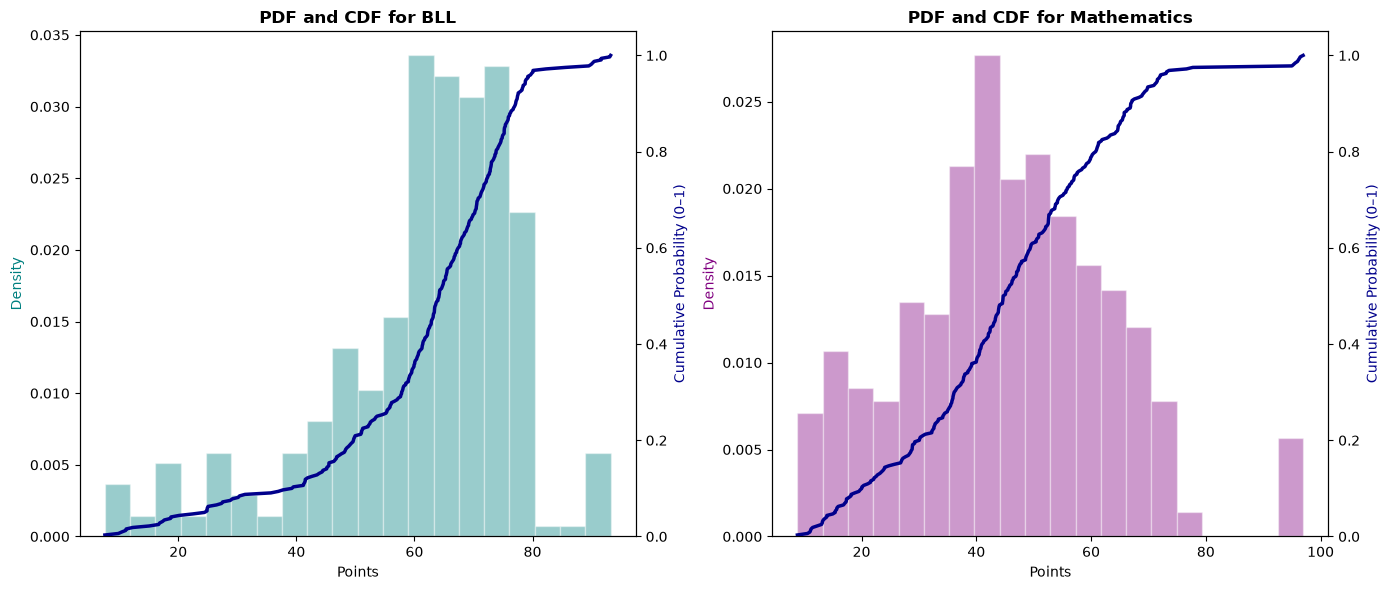

In [61]:
fig, (ax1_bel, ax1_mat) = plt.subplots(1, 2, figsize=(14, 6))

def plot_dual_pdf_cdf(ax, data, color, title):
    clean_data = data.dropna().sort_values()
    
    # PDF
    ax.hist(clean_data, bins=20, density=True, color=color, alpha=0.4, edgecolor='white', label='PDF')
    ax.set_xlabel('Points')
    ax.set_ylabel('Density', color=color)
    
    # CDF
    ax2 = ax.twinx()
    cdf_vals = np.arange(1, len(clean_data) + 1) / len(clean_data)
    ax2.plot(clean_data, cdf_vals, color='darkblue', linewidth=2.5, label='CDF')
    ax2.set_ylabel('Cumulative Probability (0–1)', color='darkblue')
    ax2.set_ylim(0, 1.05)
    
    ax.set_title(title, fontweight='bold')

plot_dual_pdf_cdf(ax1_bel, df['BLL'], 'teal', 'PDF and CDF for BLL')
plot_dual_pdf_cdf(ax1_mat, df['MATH'], 'purple', 'PDF and CDF for Mathematics')

plt.tight_layout()
plt.show()

**Analytical Findings (What Do We See in Our Data?)**

**A substantial shift in the cumulative distribution (CDF):** The Mathematics CDF rises much more steeply at the lower end of the scale than the BLL curve. Exactly 60.94% of schools in Varna have an average Mathematics score below 50 points, compared with only 20.94% for BLL.

**Percentile-based assessment of achievement:** The cumulative analysis shows that 75% of schools score up to 57.24 points in Mathematics (whereas in BLL this is close to the threshold for the lowest-performing 30% of schools). In BLL, 75% of schools score above 54.31 points, indicating a substantially better-prepared majority.

**Probability density peaks (PDF):** The BLL density peak is shifted above 60–70 points, whereas the highest density for Mathematics is concentrated around 35–45 points. This supports the identified need for methodological support in STEM.

#### 13. Analysis of Simpson's Paradox
**What it does:** Examines whether the correlation observed across the entire period retains its direction and strength when the data are broken down by individual years. Simpson's paradox occurs when a trend observed in separate subgroups disappears or reverses after aggregation.

**Why we use it:** To avoid incorrect generalizations when analyzing multi-year data.

**What it shows about our data:** We check whether the overall relationship between BLL and Mathematics remains when each year is examined separately. Aggregated data can sometimes be misleading — for example, they may show a strong overall relationship that is absent in individual cohorts because of year-specific examination characteristics.

=== SIMPSON'S PARADOX TEST ===
Overall aggregated correlation: 0.8959

Year 2018-2019: BLL–Mathematics correlation = 0.8604
Year 2019-2020: BLL–Mathematics correlation = 0.9143
Year 2020-2021: BLL–Mathematics correlation = 0.9100
Year 2021-2022: BLL–Mathematics correlation = 0.8966
Year 2022-2023: BLL–Mathematics correlation = 0.8861
Year 2023-2024: BLL–Mathematics correlation = 0.9278
Year 2024-2025: BLL–Mathematics correlation = 0.9513
Year 2025-2026: BLL–Mathematics correlation = 0.9404


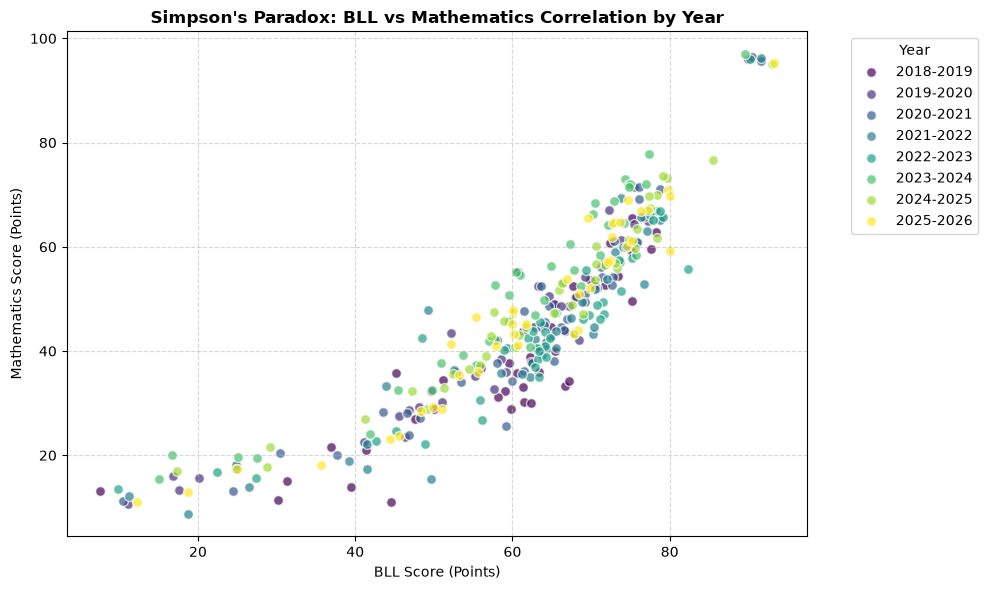

In [62]:
print("=== SIMPSON'S PARADOX TEST ===")
overall_corr = df['BLL'].corr(df['MATH'])
print(f"Overall aggregated correlation: {overall_corr:.4f}\n")

years = sorted(df['Year'].dropna().unique())
for year in years:
    sub = df[df['Year'] == year]
    print(f"Year {year}: BLL–Mathematics correlation = {sub['BLL'].corr(sub['MATH']):.4f}")

plt.figure(figsize=(10, 6))
colors = plt.cm.viridis(np.linspace(0, 1, len(years)))

for year, color in zip(years, colors):
    subset = df[df['Year'] == year]
    plt.scatter(subset['BLL'], subset['MATH'], color=color, alpha=0.7, edgecolors='w', s=50, label=f'{year}')

plt.title("Simpson's Paradox: BLL vs Mathematics Correlation by Year", fontweight='bold')
plt.xlabel('BLL Score (Points)'); plt.ylabel('Mathematics Score (Points)')
plt.legend(title="Year", bbox_to_anchor=(1.05, 1))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Analytical Findings (What Do We See in Our Data?)**

**No evidence of Simpson's paradox:** The data indicate that Simpson's paradox does not occur in the results of Varna schools. The strong positive correlation between BLL and Mathematics is consistent both at the aggregated level ($r = 0.8959$) and within every individual academic year (values ranging from 0.8604 to 0.9513).

**No hidden between-group distortion:** The results suggest that the high correlation is not an artificial effect of combining cohorts from different years. The relationship between academic achievement in humanities and STEM is consistent, and no reversal of the trend appears when the data are disaggregated.

**Increasing synchronization in recent years:** The correlation coefficient shows an upward trend in recent years, reaching a peak of 0.9513 in 2024–2025. This suggests that the academic profiles of schools in Varna have become more closely aligned — schools increasingly maintain similar relative performance levels in both subjects.

#### 14. Measuring Stability and Stratification Using the Coefficient of Variation (CV)
**What it does:** Assesses the relative variability and dispersion of results by year.

**Formula for the coefficient of variation ($CV$):**
$$CV = \left( \frac{s}{\bar{X}} \right) \times 100\%$$

**Why we use it:** To measure the relative dispersion and variability of the results.

**What it shows about our data:** By comparing the CV across years, we can assess whether educational inequality between schools in Varna is narrowing or widening over time. A higher CV in Mathematics than in BLL indicates greater relative inequality between schools in the STEM subject.

=== COEFFICIENT OF VARIATION (CV %) ===


,Year,CV_BLL,CV_MATH
0,2018-2019,26.52,44.71
1,2019-2020,29.94,40.06
2,2020-2021,27.73,40.70
3,2021-2022,27.58,41.52
4,2022-2023,27.55,38.17
5,2023-2024,27.22,35.25
6,2024-2025,24.75,33.97
7,2025-2026,27.92,39.00


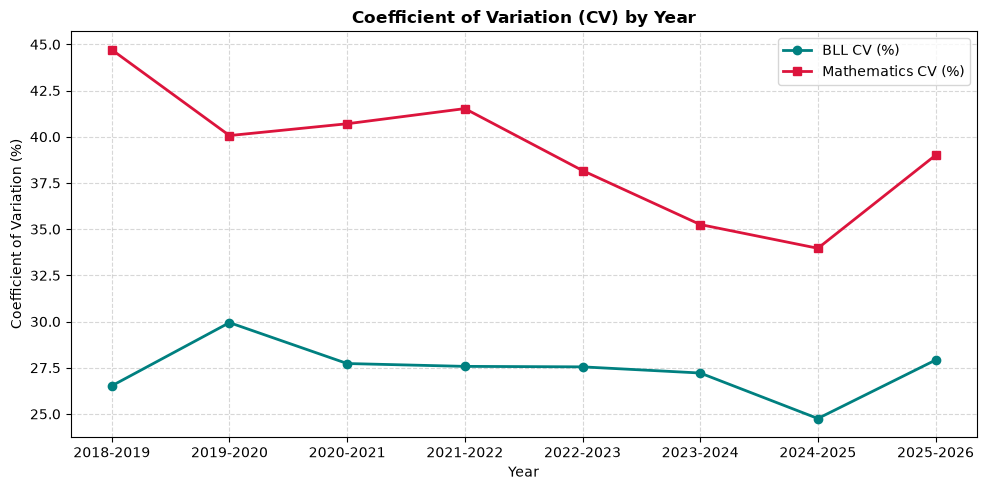

In [63]:
cv_results = []
years = sorted(df['Year'].dropna().unique())

for year in years:
    sub = df[df['Year'] == year]
    cv_bel = (sub['BLL'].std() / sub['BLL'].mean()) * 100
    cv_mat = (sub['MATH'].std() / sub['MATH'].mean()) * 100
    cv_results.append({'Year': year, 'CV_BLL': cv_bel, 'CV_MATH': cv_mat})

cv_df = pd.DataFrame(cv_results)
print("=== COEFFICIENT OF VARIATION (CV %) ===")
display(cv_df.round(2))

# Chart: Coefficient of Variation
plt.figure(figsize=(10, 5))
plt.plot(cv_df['Year'], cv_df['CV_BLL'], marker='o', color='teal', linewidth=2, label='BLL CV (%)')
plt.plot(cv_df['Year'], cv_df['CV_MATH'], marker='s', color='crimson', linewidth=2, label='Mathematics CV (%)')
plt.title('Coefficient of Variation (CV) by Year', fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Coefficient of Variation (%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

**Analytical Findings (What Do We See in Our Data?)**

**Considerably greater relative dispersion in Mathematics:** In every year examined, the coefficient of variation in Mathematics (between 33.97% and 44.71%) is considerably higher than in BLL (between 24.75% and 29.94%). Since CV values above 30% are often interpreted as indicating relatively heterogeneous datasets, this supports the conclusion that Varna schools are more polarized and unequal in their STEM achievement.

**Stable variation in BLL:** The BLL coefficient of variation remains within a narrow range around 27% throughout the eight-year period. This indicates a relatively stable level of disparity in humanities achievement between lower- and higher-performing schools in the city.

**Gradual convergence through 2024–2025, followed by a slight increase:** Between 2021 and 2025, the CV for both subjects shows a gradual decline, reaching lows of 24.75% for BLL and 33.97% for Mathematics in 2024–2025. This indicates a temporary narrowing of differences between schools. In the final year (2025–2026), however, relative dispersion increases again, returning to levels observed in the middle years of the period.

#### 15. Regression Slope (OLS Slope) by Year
**What it does:** Calculates the slope ($\beta_1$) of the linear regression $Y_{Math} = \beta_0 + \beta_1 X_{BLL} + \epsilon$ for each year separately.

**Formula for the slope ($\beta_1$):**
$$\beta_1 = \frac{\sum (X_i - \bar{X})(Y_i - \bar{Y})}{\sum (X_i - \bar{X})^2}$$

**Why we use it:** To measure the strength of the relationship between achievement in humanities and STEM over the years.

**What it shows about our data:** The slope ($\beta_1$) indicates how many additional Mathematics points are associated, on average, with a one-point increase in BLL for a school. Changes in this slope over time show whether the gap between language and mathematical skills is changing.

=== REGRESSION SLOPE (OLS Slope) ===


,Year,Slope_BLL_to_MATH
0,2018-2019,0.9441
1,2019-2020,0.9200
2,2020-2021,0.9767
3,2021-2022,0.9668
4,2022-2023,0.8635
5,2023-2024,1.0209
6,2024-2025,1.0302
7,2025-2026,1.0164


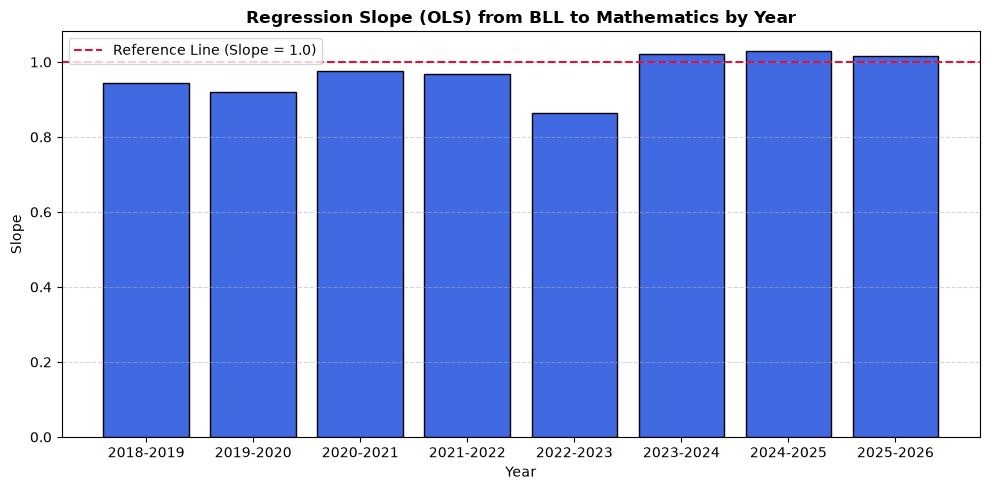

In [64]:
slope_results = []

for year in years:
    sub = df[df['Year'] == year].dropna(subset=['BLL', 'MATH'])
    if len(sub) > 2:
        slope, intercept = np.polyfit(sub['BLL'], sub['MATH'], 1)
        slope_results.append({'Year': year, 'Slope_BLL_to_MATH': slope})

slope_df = pd.DataFrame(slope_results)
print("=== REGRESSION SLOPE (OLS Slope) ===")
display(slope_df.round(4))

# Chart: Regression Slope
plt.figure(figsize=(10, 5))
plt.bar(slope_df['Year'].astype(str), slope_df['Slope_BLL_to_MATH'], color='royalblue', edgecolor='black')
plt.axhline(1.0, color='crimson', linestyle='--', label='Reference Line (Slope = 1.0)')
plt.title('Regression Slope (OLS) from BLL to Mathematics by Year', fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Slope')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

**Analytical Findings (What Do We See in Our Data?)**

**A shift from a sub-unit slope to greater sensitivity to BLL:** During the first years of the period (2018–2023), the slope is below the reference value of one ($\beta_1 < 1.0$), reaching its lowest value of 0.8635 in 2022–2023. This means that a one-point increase in BLL was associated with an increase of less than one point in Mathematics.

**A structural turning point after 2023:** In the last three academic years (2023–2024 to 2025–2026), the slope exceeds 1.0, reaching 1.0302 in 2024–2025. This indicates a change in the relationship: each additional BLL point is associated with more than one additional Mathematics point, suggesting a stronger multiplier effect of overall school achievement on STEM performance.

**Greater sensitivity of Mathematics results:** The data indicate that, in recent years, Mathematics performance has become more responsive to schools' overall academic standing in the city.

#### 16. Measuring the Gap Between Elite and At-Risk Schools (IQR Ratio)
**What it does:** Assesses educational stratification using the ratio between the upper ($Q_3$) and lower ($Q_1$) quartiles for each year.

**Formula for the quartile ratio:**
$$\text{IQR Ratio} = \frac{Q_3}{Q_1}$$

**Why we use it:** To assess educational stratification directly through the ratio between high-performing and at-risk schools.

**What it shows about our data:** If the value of $Q_3 / Q_1$ increases over the years, this indicates a widening gap — the top 25% of schools improve or maintain their positions while the bottom 25% fall further behind, pointing to a growing challenge in ensuring equal access to quality educational outcomes.

=== Q3/Q1 RATIO (GAP MEASUREMENT) ===


,Year,Q3/Q1_BLL,Q3/Q1_MATH
0,2018-2019,1.342,1.690
1,2019-2020,1.355,1.648
2,2020-2021,1.341,1.656
3,2021-2022,1.295,1.659
4,2022-2023,1.237,1.438
5,2023-2024,1.278,1.612
6,2024-2025,1.329,1.590
7,2025-2026,1.378,1.708


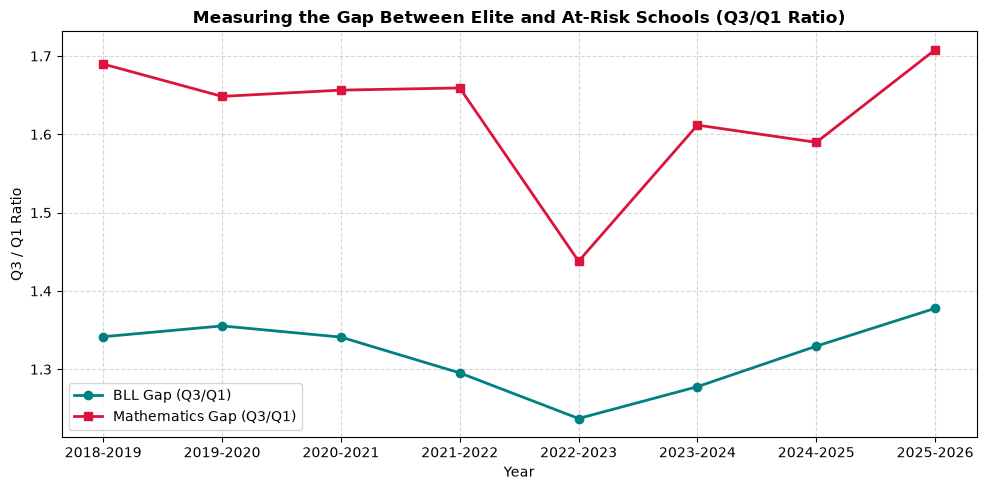

In [65]:
def get_quartile_ratio(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    return q3 / q1 if q1 > 0 else np.nan

ratio_results = []
for year in years:
    sub = df[df['Year'] == year]
    ratio_bel = get_quartile_ratio(sub, 'BLL')
    ratio_mat = get_quartile_ratio(sub, 'MATH')
    ratio_results.append({'Year': year, 'Q3/Q1_BLL': ratio_bel, 'Q3/Q1_MATH': ratio_mat})

ratio_df = pd.DataFrame(ratio_results)
print("=== Q3/Q1 RATIO (GAP MEASUREMENT) ===")
display(ratio_df.round(3))

# Chart: Gap Between Elite and At-Risk Schools
plt.figure(figsize=(10, 5))
plt.plot(ratio_df['Year'], ratio_df['Q3/Q1_BLL'], marker='o', color='teal', linewidth=2, label='BLL Gap (Q3/Q1)')
plt.plot(ratio_df['Year'], ratio_df['Q3/Q1_MATH'], marker='s', color='crimson', linewidth=2, label='Mathematics Gap (Q3/Q1)')
plt.title('Measuring the Gap Between Elite and At-Risk Schools (Q3/Q1 Ratio)', fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Q3 / Q1 Ratio')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

**Analytical Findings (What Do We See in Our Data?)**

**A substantially wider gap in Mathematics:** In every academic year, the $Q_3/Q_1$ ratio in Mathematics (between 1.438 and 1.708) is considerably higher than in BLL (between 1.237 and 1.378). The value of 1.708 in the final year indicates that the top 25% of schools in Varna ($Q_3$) achieve results more than 70% higher in STEM than schools in the bottom 25% ($Q_1$).

**A comparatively narrower and more stable distribution in BLL:** In the humanities subject, the gap is considerably smaller — schools in the third quartile outperform those in the first quartile by only around 24–38%. This reinforces the observed homogeneity and higher overall level of mastery in BLL.

**Temporary narrowing followed by widening:** Both subjects show a decline, with the narrowest gap in 2022–2023 (1.237 for BLL and 1.438 for Mathematics), followed by a clear and continuous widening through 2025–2026. The final year records the widest gap in the sample (1.708 in Mathematics and 1.378 in BLL).

### Conclusion
The longitudinal study of National External Assessment (NEA) results in the city of Varna for the period 2018–2026 reveals deep structural patterns in achievement in Bulgarian Language and Literature (BLL) and Mathematics (Math).

**Systemic imbalance between subjects:**
The city's mean BLL score ($\mu = 60.99$ points, median $= 64.18$ points) exceeds the Mathematics mean ($\mu = 45.51$ points, median $= 44.88$ points) by more than 15.5 points. The cumulative distribution analysis (CDF) shows that 60.94% of schools in Varna have an average Mathematics score below 50 points, compared with only 20.94% in BLL.

**Changes in educational stratification and variation:**
The $Q_3/Q_1$ ratio (IQR Ratio) reveals that the gap between the top 25% and bottom 25% of schools is considerably wider in STEM, reaching a record high of 1.708 in 2025–2026 in Mathematics, compared with 1.378 in BLL. The elevated coefficient of variation ($CV > 33\%-44\%$ in Mathematics) indicates substantial heterogeneity in STEM achievement.

**Temporal stability versus volatility (ANOVA):**
The one-way analysis of variance indicates that BLL results are statistically stable across the eight-year period ($F = 0.4202, p = 0.889$). In contrast, Mathematics results show statistically significant differences between cohorts ($F = 2.2372, p = 0.0312$), highlighting the subject's sensitivity to examination difficulty and year-to-year preparation.

**Strong institutional correlation and OLS sensitivity:**
Pearson's correlation between the two subjects is very high ($r = 0.8959$) and remains consistent across years, with no evidence of Simpson's paradox. The regression slope ($\beta_1$) exceeds 1.0 after 2023, suggesting that a school's overall academic capacity is associated with a multiplier effect on STEM performance.

**Characteristics of outliers (IQR Outliers):**
In BLL, all 21 identified outliers are at the lower end of the distribution (underperforming schools with scores below 27 points), whereas all 8 Mathematics outliers are at the upper end (elite institutions scoring above 91.6 points, led by Dr. Petar Beron Mathematics High School).

### Policy Implications
Based on the mathematical and statistical evidence obtained, the following strategic recommendations emerge for the Ministry of Education and Science, the Regional Department of Education in Varna, and school leadership teams:

**Targeted support for at-risk schools (BLL):**
Since BLL outliers are concentrated entirely in the lower tail (as indicated by negative skewness, $S_k = -1.14$), specialized language programmes should be introduced in schools with results below the threshold of 27.01 points to address the emerging low-performing group.

**A national/regional programme to strengthen Mathematics education:**
The very low median Mathematics score (44.88 points) across mainstream schools calls for a review of curricula, teaching methods at lower-secondary level, and greater emphasis on practical applications in problem-solving.

**Narrowing the gap between elite and lower-performing schools:**
The gradual widening of the $Q_3/Q_1$ ratio in Mathematics after 2023 calls for resource support for schools outside the top 15, in order to prevent deeper educational segregation in the city.

**Sustained sharing of good practices:**
The exceptional stability of Dr. Petar Beron Mathematics High School ($\sigma_{overall} = 0.46$) and leading primary schools provides a reference model for educational management that should be studied and scaled across the municipality.

#### Literature and References
1. Pandas Development Team. (2024). *pandas: powerful Python data analysis toolkit*. https://pandas.pydata.org/
2. Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95.
3. Virtanen, P. et al. (2020). SciPy 1.0: Fundamental Algorithms for Scientific Computing in Python. *Nature Methods, 17*, 261–272.
4. Mathematical concepts - Wikipedia:
        https://en.wikipedia.org/wiki/Arithmetic_mean
        https://en.wikipedia.org/wiki/Median
        https://en.wikipedia.org/wiki/Standard_deviation
        https://en.wikipedia.org/wiki/Maximum_and_minimum
        https://en.wikipedia.org/wiki/Pearson_correlation_coefficient
        https://en.wikipedia.org/wiki/Skewness
        https://en.wikipedia.org/wiki/Kurtosis
        https://en.wikipedia.org/wiki/Central_limit_theorem
        https://en.wikipedia.org/wiki/Interquartile_range
        https://en.wikipedia.org/wiki/One-way_analysis_of_variance
        https://en.wikipedia.org/wiki/Cumulative_distribution_function
        https://en.wikipedia.org/wiki/Probability_density_function
        https://en.wikipedia.org/wiki/Simpson%27s_paradox
        https://en.wikipedia.org/wiki/Coefficient_of_variation
        https://en.wikipedia.org/wiki/Linear_regression
5. Open data from the National External Assessment (NEA).
       https://nvoresults.com/index.html?grade=7&year=2025-2026&region=%D0%92%D0%90%D0%A0%D0%9D%D0%90&city=%D0%93%D0%A0.+%D0%92%D0%90%D0%A0%D0%9D%D0%90
       https://nvoresults.com/index.html?grade=7&year=2024-2025&region=%D0%92%D0%90%D0%A0%D0%9D%D0%90&city=%D0%93%D0%A0.+%D0%92%D0%90%D0%A0%D0%9D%D0%90
       https://nvoresults.com/index.html?grade=7&year=2023-2024&region=%D0%92%D0%90%D0%A0%D0%9D%D0%90&city=%D0%93%D0%A0.+%D0%92%D0%90%D0%A0%D0%9D%D0%90
       https://nvoresults.com/index.html?grade=7&year=2022-2023&region=%D0%92%D0%90%D0%A0%D0%9D%D0%90&city=%D0%93%D0%A0.+%D0%92%D0%90%D0%A0%D0%9D%D0%90
       https://nvoresults.com/index.html?grade=7&year=2021-2022&region=%D0%92%D0%90%D0%A0%D0%9D%D0%90&city=%D0%93%D0%A0.+%D0%92%D0%90%D0%A0%D0%9D%D0%90
       https://nvoresults.com/index.html?grade=7&year=2020-2021&region=%D0%92%D0%90%D0%A0%D0%9D%D0%90&city=%D0%93%D0%A0.+%D0%92%D0%90%D0%A0%D0%9D%D0%90
       https://nvoresults.com/index.html?grade=7&year=2019-2020&region=%D0%92%D0%90%D0%A0%D0%9D%D0%90&city=%D0%93%D0%A0.+%D0%92%D0%90%D0%A0%D0%9D%D0%90
       https://nvoresults.com/index.html?grade=7&year=2018-2019&region=%D0%92%D0%90%D0%A0%D0%9D%D0%90&city=%D0%93%D0%A0.+%D0%92%D0%90%D0%A0%D0%9D%D0%90